# 08 · Neural network in CPTAC and SMC (strategies 1, 2 and 3)

This notebook runs the three network strategies in the target cohorts. Here the network sees CPTAC and SMC **for the first time**. Everything was fixed before, without looking at these cohorts: exams and repetitions (notebook 04), the network (06) and how to adjust it (07). **Nothing is chosen in this notebook.**

| Strategy | What it does |
|---|---|
| **1. Apply directly** | The source network (TCGA + METABRIC), as it is |
| **2. Fine-tuning** | The source network, adjusted with n local patients (every layer) |
| **3. From scratch** | The same shape of network, with new weights, trained only with the n local patients |

Strategy 2 starts from what the network learned with 2,860 patients. Strategy 3 starts from zero. Both use the same network shape, the same patients and the same seed in each repetition. The learning rate and epochs of each one were chosen in notebook 07.

**Two fine-tuning settings (decision of 14-Oct-2026):**
1. **Main:** learning rate 1e-5 and 10 epochs, the one chosen in notebook 07. Every setting tied in AUC (~0.865), and the tie-break (smallest SD) chose the one that changes the network the least.
2. **Sensitivity:** learning rate 1e-4 and 10 epochs. It also tied in AUC in notebook 07, but it does change the network (SD 0.008 against 0.002). It shows whether the higher stability of fine-tuning holds when the network really changes.

Both are reported. The best one is not chosen.

**Output** (in `data/experiment/`): `auc_red.csv` (AUC on the exam and on the network's own local patients, `auc_locales`), `prob_red.parquet` (probability of each exam patient) and `perdida_red.parquet` (training loss per epoch).

**Time:** 13,510 networks, about 3.5 hours on the Khipu cluster. It saves after each exam.

*Note: this notebook was run before the repository was translated. The code comments, printed text and figure labels in the saved outputs are in Spanish. The results are the same.*

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import armar_red, cargar, pesos_clase, zscore  # common sets Keras to run on PyTorch before keras is imported

import keras

EXP = ROOT / "data" / "experiment"
FIG = ROOT / "results" / "figures"
TAB = ROOT / "results" / "tables"
PARTS = EXP / "partes_08"
PARTS.mkdir(exist_ok=True)

TARGETS = ["CPTAC", "SMC 2018"]
NAMES = {1: "1. Aplicar directo", 2: "2. Ajuste fino", 3: "3. Desde cero"}
COLORS = {2: "#534AB7", 3: "#D85A30"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Step 1 · What is already fixed

In [2]:
arch = json.loads((TAB / "06_elegida.json").read_text())
chosen = json.loads((TAB / "07_ajuste_elegido.json").read_text())
SETUPS = {(2, "principal"): chosen["ajuste_fino"], (2, "sensibilidad"): {"tasa": 1e-4, "epocas": 10},
          (3, "principal"): chosen["desde_cero"]}
source = keras.models.load_model(EXP / "red_fuente.keras")
source_weights = source.get_weights()

pd.DataFrame({"Red (06)": {"capas": arch["capas"], "lote (preentrenamiento)": arch["lote"], "dropout": arch["dropout"],
                           "optimizador": arch["optimizador"], "épocas (preentrenamiento)": arch["epocas"]},
              **{f"{NAMES[s]} ({v})": {"tasa": c["tasa"], "épocas": c["epocas"]} for (s, v), c in SETUPS.items()}})

,Red (06),2. Ajuste fino (principal),2. Ajuste fino (sensibilidad),3. Desde cero (principal)
capas,[256],NaN,NaN,NaN
lote (preentrenamiento),16,NaN,NaN,NaN
dropout,0.3,NaN,NaN,NaN
optimizador,sgd,NaN,NaN,NaN
épocas (preentrenamiento),19,NaN,NaN,NaN
tasa,NaN,0.00001,0.0001,0.001
épocas,NaN,10.00000,10.0000,100.000


## Step 2 · Run the three strategies

For each cohort and each exam:
1. Normalize the cohort with the patients that are **not** in the exam, without labels (same as notebook 05).
2. **Strategy 1:** the source network on the 40 exam patients.
3. For each n and each of the 100 repetitions, with the same local patients that ElasticNet used:
   - **Strategy 2:** the source network is copied and adjusted with the n local patients, with the two settings (main and sensitivity).
   - **Strategy 3:** the same network is built with new weights and trained only with the n local patients.
   - Both use **batch = all n patients together**, class weights and **seed = repetition number**, as in the rehearsal.
   - The probability of each exam patient, the AUC on the network's own local patients (for the gap) and the training loss per epoch are saved.

In [3]:
exams = pd.read_csv(EXP / "examenes.csv")
reps = pd.read_csv(EXP / "repeticiones.csv")


def train(strategy, setup, rep, x_loc, y_loc):
    keras.utils.set_random_seed(rep)
    model = armar_red(arch["capas"], arch["dropout"], setup["tasa"], arch["optimizador"])
    if strategy == 2:
        model.set_weights(source_weights)
    h = model.fit(x_loc, y_loc, batch_size=len(y_loc), epochs=setup["epocas"],
                  class_weight=pesos_clase(y_loc), verbose=0).history
    return model, h["loss"]


for name in TARGETS:
    x, y = cargar(name)
    for e in range(1, 6):
        part = PARTS / f"{name.replace(' ', '_')}_examen{e}.parquet"
        if part.exists():
            continue
        start = time.time()
        exam_ids = exams.query("cohorte == @name and examen == @e").muestra
        z = zscore(x, x.index.difference(exam_ids))
        x_exam, y_exam = z.loc[exam_ids].to_numpy(), y.loc[exam_ids].to_numpy()
        groups = reps.query("cohorte == @name and examen == @e").groupby(["n", "repeticion"]).muestra.apply(list)

        probs = [(1, "principal", 0, 0, np.nan, source.predict(x_exam, verbose=0).ravel())]
        losses = []
        for (n, r), ids in groups.items():
            x_loc, y_loc = z.loc[ids].to_numpy(), y.loc[ids].to_numpy()
            for (s, v), setup in SETUPS.items():
                model, loss = train(s, setup, r, x_loc, y_loc)
                auc_loc = roc_auc_score(y_loc, model.predict(x_loc, verbose=0).ravel())
                probs.append((s, v, n, r, auc_loc, model.predict(x_exam, verbose=0).ravel()))
                losses.append(pd.DataFrame({"estrategia": s, "variante": v, "n": n, "repeticion": r,
                                            "epoca": np.arange(1, len(loss) + 1), "perdida": loss}))

        out = pd.DataFrame([{"cohorte": name, "examen": e, "estrategia": s, "variante": v, "n": n, "repeticion": r,
                             "auc_locales": a, "muestra": m, "y": t, "prob": p}
                            for s, v, n, r, a, ps in probs for m, t, p in zip(exam_ids, y_exam, ps)])
        out.to_parquet(part)
        pd.concat(losses).assign(cohorte=name, examen=e).to_parquet(PARTS / f"perdida_{name.replace(' ', '_')}_examen{e}.parquet")
        print(f"{name} examen {e}: {len(probs):,} redes en {(time.time() - start) / 60:.0f} min")

CPTAC examen 1: 1,201 redes en 14 min


CPTAC examen 2: 1,201 redes en 15 min


CPTAC examen 3: 1,201 redes en 14 min


CPTAC examen 4: 1,201 redes en 13 min


CPTAC examen 5: 1,201 redes en 13 min


SMC 2018 examen 1: 1,501 redes en 32 min


SMC 2018 examen 2: 1,501 redes en 24 min


SMC 2018 examen 3: 1,501 redes en 26 min


SMC 2018 examen 4: 1,501 redes en 32 min


SMC 2018 examen 5: 1,501 redes en 30 min


## Step 3 · Join and compute the AUC

The AUC of each network is computed with the probability and the real label of the 40 exam patients.

In [4]:
prob = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("*_examen*.parquet")) if not p.name.startswith("perdida")],
                 ignore_index=True)
loss = pd.concat([pd.read_parquet(p) for p in sorted(PARTS.glob("perdida_*.parquet"))], ignore_index=True)
keys = ["cohorte", "examen", "estrategia", "variante", "n", "repeticion"]
auc = (prob.groupby(keys).agg(auc_locales=("auc_locales", "first")).join(
       prob.groupby(keys)[["y", "prob"]].apply(lambda g: roc_auc_score(g.y, g.prob)).rename("auc"))).reset_index()
assert auc.groupby(["cohorte", "estrategia", "variante", "n"]).size().isin([5, 500]).all(), "faltan redes"
assert auc.auc.notna().all()

auc[keys + ["auc", "auc_locales"]].to_csv(EXP / "auc_red.csv", index=False)
prob.drop(columns=["y", "auc_locales"]).to_parquet(EXP / "prob_red.parquet")
loss.to_parquet(EXP / "perdida_red.parquet")
print(f"{len(auc):,} AUC guardados")

13,510 AUC guardados


## Step 4 · Quick check (not the final analysis)

The full analysis, with the Pitman-Morgan and Stouffer tests, is in notebook 09. Here we only check that everything makes sense.

In [5]:
per_exam = auc.groupby(["cohorte", "estrategia", "variante", "n", "examen"]).agg(auc=("auc", "mean"), de=("auc", "std"),
                                                                     brecha=("auc_locales", "mean"))
per_exam["brecha"] -= per_exam.auc
summary = per_exam.groupby(["cohorte", "estrategia", "variante", "n"]).mean().round(3)
summary.columns = ["AUC promedio", "DE entre repeticiones", "Brecha (locales − examen)"]
summary

AUC promedio  DE entre repeticiones  \
cohorte  estrategia variante     n                                         
CPTAC    1          principal    0          0.933                    NaN   
         2          principal    10         0.933                  0.001   
                                 15         0.933                  0.001   
                                 20         0.933                  0.001   
                                 40         0.933                  0.000   
                    sensibilidad 10         0.933                  0.009   
                                 15         0.933                  0.007   
                                 20         0.934                  0.005   
                                 40         0.935                  0.003   
         3          principal    10         0.789                  0.116   
                                 15         0.820                  0.088   
                                 20         0.841                  0.070   
                                 40         0.880                  0.040   
SMC 2018 1          principal    0          0.866                    NaN   
         2          principal    10         0.867                  0.002   
                                 15         0.867                  0.002   
                                 20         0.867                  0.002   
                                 40         0.867                  0.001   
                                 80         0.866                  0.001   
                    sensibilidad 10         0.867                  0.009   
                                 15         0.868                  0.008   
                                 20         0.869                  0.007   
                                 40         0.870                  0.005   
                                 80         0.870                  0.004   
         3          principal    10         0.677                  0.093   
                                 15         0.702                  0.072   
                                 20         0.718                  0.065   
                                 40         0.753                  0.050   
                                 80         0.772                  0.030   

                                     Brecha (locales − examen)  
cohorte  estrategia variante     n                              
CPTAC    1          principal    0                         NaN  
         2          principal    10                     -0.070  
                                 15                     -0.079  
                                 20                     -0.077  
                                 40                     -0.086  
                    sensibilidad 10                      0.058  
                                 15                      0.038  
                                 20                      0.031  
                                 40                     -0.033  
         3          principal    10                      0.211  
                                 15                      0.180  
                                 20                      0.159  
                                 40                      0.120  
SMC 2018 1          principal    0                         NaN  
         2          principal    10                      0.019  
                                 15                      0.015  
                                 20                      0.014  
                                 40                      0.012  
                                 80                      0.009  
                    sensibilidad 10                      0.131  
                                 15                      0.119  
                                 20                      0.100  
                                 40                      0.056  
                                 80                    

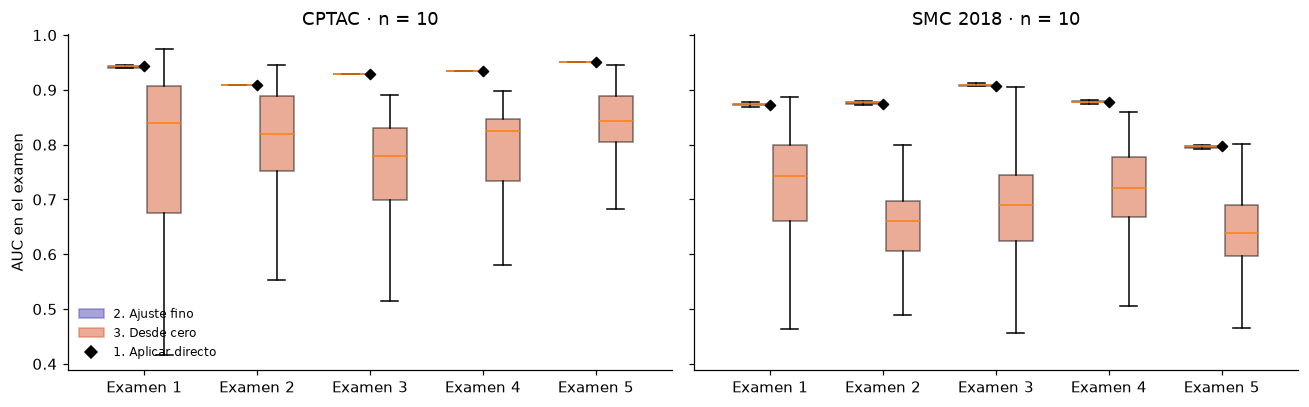

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, name in zip(axes, TARGETS):
    d = auc[(auc.cohorte == name) & (auc.n.isin([0, 10])) & (auc.variante == "principal")]
    for e in range(1, 6):
        for k, s in enumerate((2, 3)):
            v = d[(d.examen == e) & (d.estrategia == s)].auc
            box = ax.boxplot(v, positions=[e + (k - 0.5) * 0.35], widths=0.3, patch_artist=True, showfliers=False)
            box["boxes"][0].set(facecolor=COLORS[s], alpha=0.5)
        ax.scatter(e, d[(d.examen == e) & (d.estrategia == 1)].auc, color="black", marker="D", s=22, zorder=3)
    ax.set_xticks(range(1, 6), [f"Examen {e}" for e in range(1, 6)])
    ax.set_title(f"{name} · n = 10")
axes[0].set_ylabel("AUC en el examen")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[s], alpha=0.5) for s in (2, 3)]
handles.append(plt.Line2D([], [], color="black", marker="D", ls="none"))
axes[0].legend(handles, [NAMES[2], NAMES[3], NAMES[1]], frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
fig.savefig(FIG / "08_vistazo_n10.png", bbox_inches="tight")

Only the main fine-tuning setting. Each box shows the 100 AUCs of one strategy in one exam, depending on which 10 patients were drawn. A shorter box is a more stable strategy. The black diamond is "apply directly" (one value per exam).

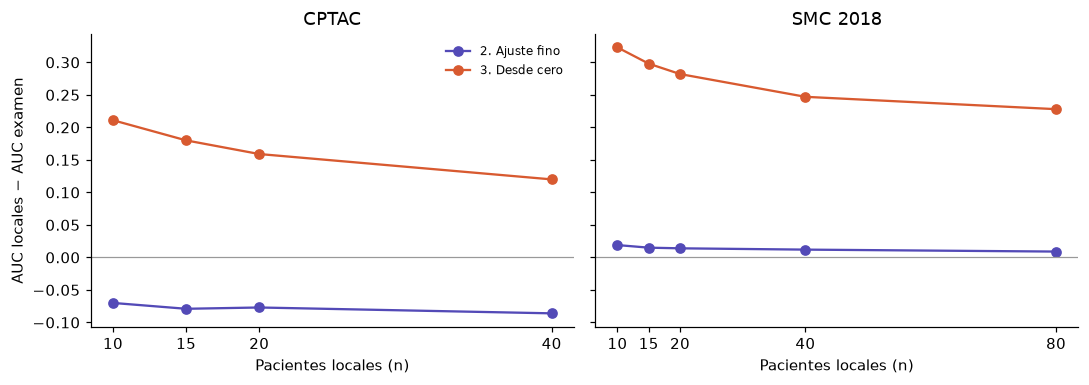

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, TARGETS):
    for s in (2, 3):
        t = summary.loc[(name, s, "principal")]
        ax.plot(t.index, t["Brecha (locales − examen)"], marker="o", color=COLORS[s], label=NAMES[s])
    ax.axhline(0, color="#999999", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Pacientes locales (n)")
    ax.set_xticks(summary.loc[(name, 2, "principal")].index)
axes[0].set_ylabel("AUC locales − AUC examen")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "08_brecha_vs_n.png", bbox_inches="tight")

The gap is how much better the network does on its own local patients than on new patients. A big gap means it memorized its few patients (overfitting). If the pretrained network has a smaller gap than the network from scratch, pretraining protects against memorization.

In CPTAC the gap of main fine-tuning is negative. The reason is that the local patients come from outside the exam, and the CPTAC exams turned out easier than the rest of the cohort.

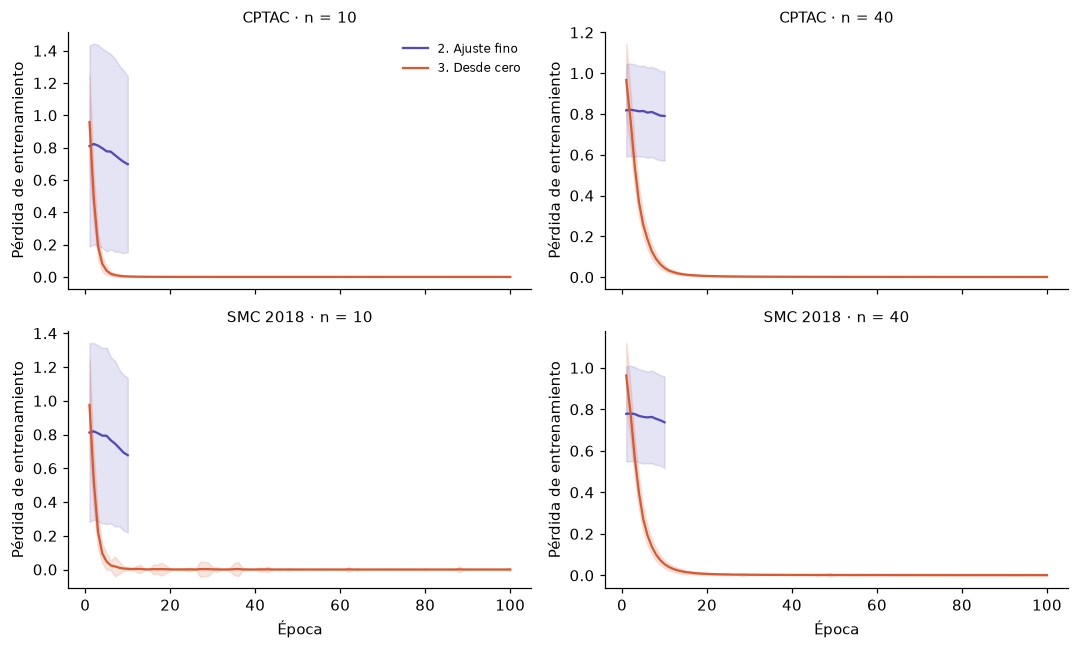

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex="col")
for i, name in enumerate(TARGETS):
    for j, n in enumerate([10, 40]):
        ax = axes[i, j]
        for s in (2, 3):
            d = loss[(loss.cohorte == name) & (loss.n == n) & (loss.estrategia == s) & (loss.variante == "principal")].groupby("epoca").perdida
            m, sd = d.mean(), d.std()
            ax.plot(m.index, m, color=COLORS[s], label=NAMES[s])
            ax.fill_between(m.index, m - sd, m + sd, color=COLORS[s], alpha=0.15)
        ax.set_title(f"{name} · n = {n}", fontsize=10)
        ax.set_ylabel("Pérdida de entrenamiento")
for ax in axes[1]:
    ax.set_xlabel("Época")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "08_perdida_entrenamiento.png", bbox_inches="tight")

This is a check. It shows that fine-tuning and the network from scratch did train (the loss goes down). It only uses the local patients. **Nothing of the exam is plotted per epoch**, because looking at the exam AUC epoch by epoch invites choosing the epochs with the exam, which is exactly what is avoided. The epochs were already fixed in the rehearsal (notebook 07).